
JARVIS18
Original shape: (18964, 145)
Removing outcome columns: ['e_form', 'bulk_modulus', 'bandgap']
Final number of features: 141
Maximum absolute correlation: 0.8496

JARVIS22
Original shape: (23472, 149)
Removing outcome columns: ['e_form', 'bulk_modulus', 'bandgap']
Final number of features: 145
Maximum absolute correlation: 0.8495

MP18
Original shape: (6979, 142)
Removing outcome columns: ['e_form', 'bulk_modulus', 'bandgap']
Final number of features: 138
Maximum absolute correlation: 0.8494

MP21
Original shape: (7112, 142)
Removing outcome columns: ['e_form', 'bulk_modulus', 'bandgap']
Final number of features: 138
Maximum absolute correlation: 0.8500

Figure saved to:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2\WITH_MODIFICATIONS\feature_pearson_correlation_heatmaps.png


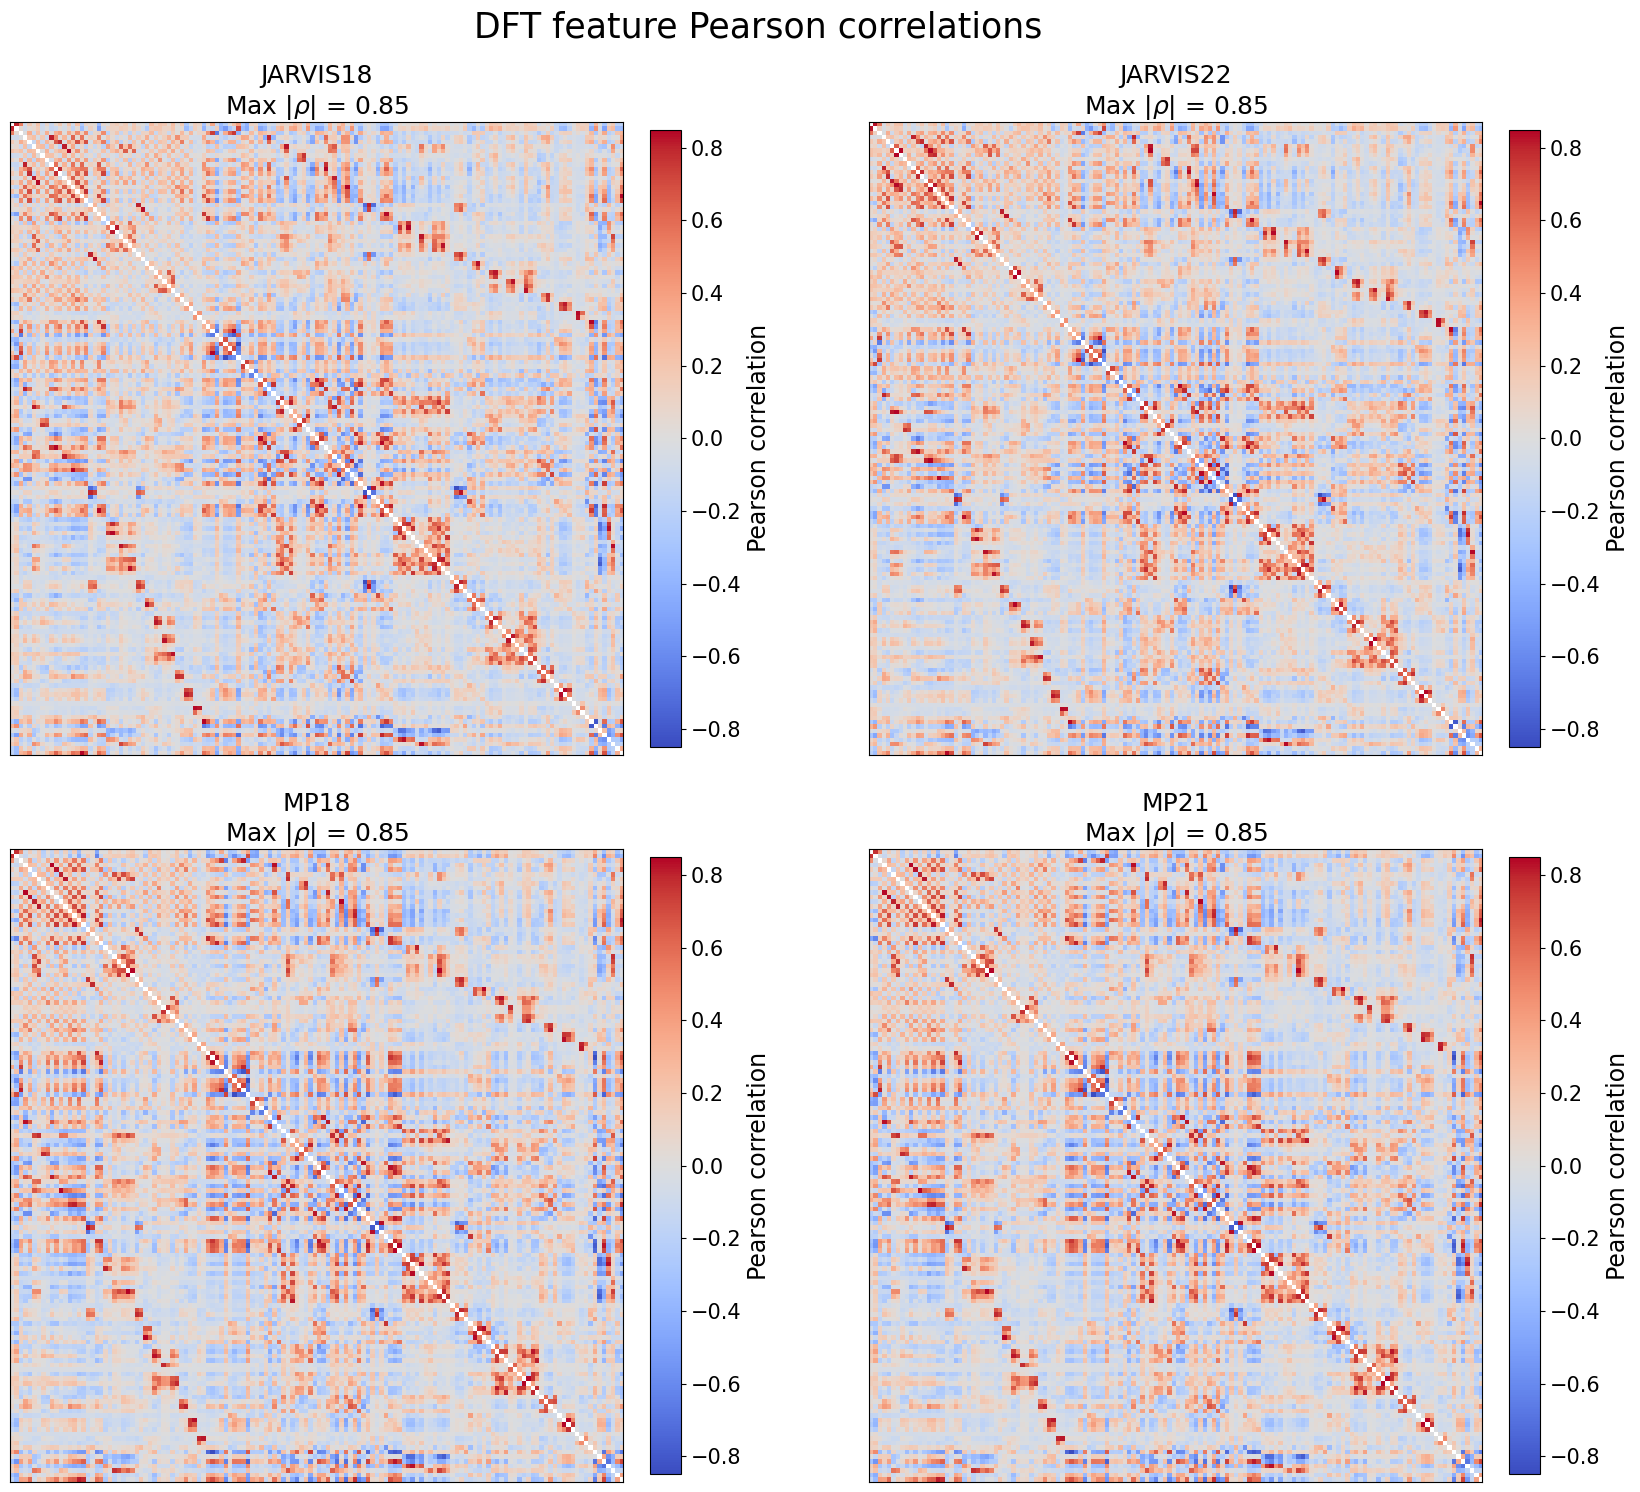

In [8]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


# =============================================================================
# Paths
# =============================================================================

DATASETS = {
    "JARVIS18": Path(
        r"C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES"
        r"\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2"
        r"\WITH_MODIFICATIONS\alldata_ColFilterjarvis18.csv"
    ),

    "JARVIS22": Path(
        r"C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES"
        r"\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2"
        r"\WITH_MODIFICATIONS\alldata_ColFilterjarvis22.csv"
    ),

    "MP18": Path(
        r"C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES"
        r"\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2"
        r"\WITH_MODIFICATIONS\alldata_ColFiltermp18.csv"
    ),

    "MP21": Path(
        r"C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES"
        r"\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2"
        r"\WITH_MODIFICATIONS\alldata_ColFiltermp21.csv"
    ),
}


# =============================================================================
# Outcome columns to exclude
# =============================================================================

OUTCOME_COLUMNS = [
    "e_form",
    "bulk_modulus",
    "bandgap",
]


# =============================================================================
# Heatmap function
# =============================================================================

def draw_corr_heatmap(ax, corr, title):

    # Copy correlation matrix
    corr_plot = corr.copy()

    # -------------------------------------------------------------------------
    # Remove diagonal
    # -------------------------------------------------------------------------
    np.fill_diagonal(corr_plot.values, np.nan)

    # -------------------------------------------------------------------------
    # Find maximum absolute off-diagonal correlation
    # -------------------------------------------------------------------------
    max_corr = np.nanmax(
        np.abs(corr_plot.values)
    )

    # Protect against degenerate case
    if max_corr == 0 or np.isnan(max_corr):
        max_corr = 1.0

    # -------------------------------------------------------------------------
    # Colormap
    # -------------------------------------------------------------------------
    cmap = plt.colormaps["coolwarm"].copy()

    # Diagonal will appear white
    cmap.set_bad("white")

    # -------------------------------------------------------------------------
    # Heatmap
    # -------------------------------------------------------------------------
    im = ax.imshow(
        corr_plot.values,
        vmin=-max_corr,
        vmax=max_corr,
        cmap=cmap,
        interpolation="none",
        aspect="auto"
    )

    n_features = len(corr.columns)

    # -------------------------------------------------------------------------
    # Axis labels
    # -------------------------------------------------------------------------
    if n_features <= 50:

        ax.set_xticks(
            np.arange(n_features)
        )

        ax.set_yticks(
            np.arange(n_features)
        )

        ax.set_xticklabels(
            corr.columns,
            rotation=90,
            fontsize=6
        )

        ax.set_yticklabels(
            corr.index,
            fontsize=6
        )

    else:

        # For matrices with many features,
        # showing every feature name becomes unreadable
        ax.set_xticks([])
        ax.set_yticks([])

    # -------------------------------------------------------------------------
    # Title
    # -------------------------------------------------------------------------
    ax.set_title(
    f"{title}\nMax $|\\rho|$ = {max_corr:.2f}",
    fontsize=18)

    return im, max_corr


# =============================================================================
# Create figure
# =============================================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(17, 16)
)

axes = axes.flatten()


# =============================================================================
# Loop over datasets
# =============================================================================

for ax, (dataset_name, path) in zip(
    axes,
    DATASETS.items()
):

    print("\n" + "=" * 70)
    print(dataset_name)
    print("=" * 70)

    # -------------------------------------------------------------------------
    # Read CSV
    # -------------------------------------------------------------------------
    df = pd.read_csv(path)

    print(
        f"Original shape: {df.shape}"
    )

    # -------------------------------------------------------------------------
    # Remove first column
    #
    # This column contains the row indices.
    # -------------------------------------------------------------------------
    df = df.iloc[:, 1:].copy()

    # -------------------------------------------------------------------------
    # Remove any remaining unnamed columns
    # -------------------------------------------------------------------------
    unnamed_columns = [
        col
        for col in df.columns
        if str(col).startswith("Unnamed")
    ]

    if unnamed_columns:

        print(
            f"Removing unnamed columns: "
            f"{unnamed_columns}"
        )

        df = df.drop(
            columns=unnamed_columns
        )

    # -------------------------------------------------------------------------
    # Remove outcome columns
    #
    # We want correlations only between FEATURES.
    # -------------------------------------------------------------------------
    outcome_columns_present = [
        col
        for col in OUTCOME_COLUMNS
        if col in df.columns
    ]

    if outcome_columns_present:

        print(
            f"Removing outcome columns: "
            f"{outcome_columns_present}"
        )

        df = df.drop(
            columns=outcome_columns_present
        )

    # -------------------------------------------------------------------------
    # Convert all remaining columns to numeric
    # -------------------------------------------------------------------------
    data = df.apply(
        pd.to_numeric,
        errors="coerce"
    )

    # -------------------------------------------------------------------------
    # Remove columns that contain only NaN
    # -------------------------------------------------------------------------
    all_nan_columns = data.columns[
        data.isna().all()
    ].tolist()

    if all_nan_columns:

        print(
            f"Removing {len(all_nan_columns)} "
            "non-numeric / completely empty columns."
        )

        data = data.drop(
            columns=all_nan_columns
        )

    # -------------------------------------------------------------------------
    # Remove constant columns
    #
    # Pearson correlation is undefined for a constant feature.
    # -------------------------------------------------------------------------
    constant_columns = [
        col
        for col in data.columns
        if data[col].nunique(dropna=True) <= 1
    ]

    if constant_columns:

        print(
            f"Removing {len(constant_columns)} "
            "constant features."
        )

        data = data.drop(
            columns=constant_columns
        )

    print(
        f"Final number of features: "
        f"{data.shape[1]}"
    )

    # -------------------------------------------------------------------------
    # Pearson correlation among FEATURES
    # -------------------------------------------------------------------------
    corr = data.corr(
        method="pearson"
    )

    # -------------------------------------------------------------------------
    # Draw heatmap
    # -------------------------------------------------------------------------
    im, max_corr = draw_corr_heatmap(
        ax,
        corr,
        dataset_name
    )

    # -------------------------------------------------------------------------
    # Individual colorbar
    #
    # Each dataset has its own range:
    #
    # -max(|r|) --> +max(|r|)
    # -------------------------------------------------------------------------
    cbar = fig.colorbar(
        im,
        ax=ax,
        fraction=0.046,
        pad=0.04
    )

    cbar.set_label(
        "Pearson correlation",
        fontsize=17
    )

    cbar.ax.tick_params(
        labelsize=15
    )

    print(
        f"Maximum absolute correlation: "
        f"{max_corr:.4f}"
    )


# =============================================================================
# Global formatting
# =============================================================================

fig.suptitle(
    "DFT feature Pearson correlations",
    fontsize=25,
    y=0.98
)

fig.subplots_adjust(
    left=0.06,
    right=0.96,
    bottom=0.06,
    top=0.91,
    wspace=0.28,
    hspace=0.15
)


# =============================================================================
# Save figure
# =============================================================================

output_path = Path(
    r"C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES"
    r"\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2"
    r"\WITH_MODIFICATIONS\feature_pearson_correlation_heatmaps.png"
)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

print("\nFigure saved to:")
print(output_path)


# =============================================================================
# Show figure
# =============================================================================

plt.show()

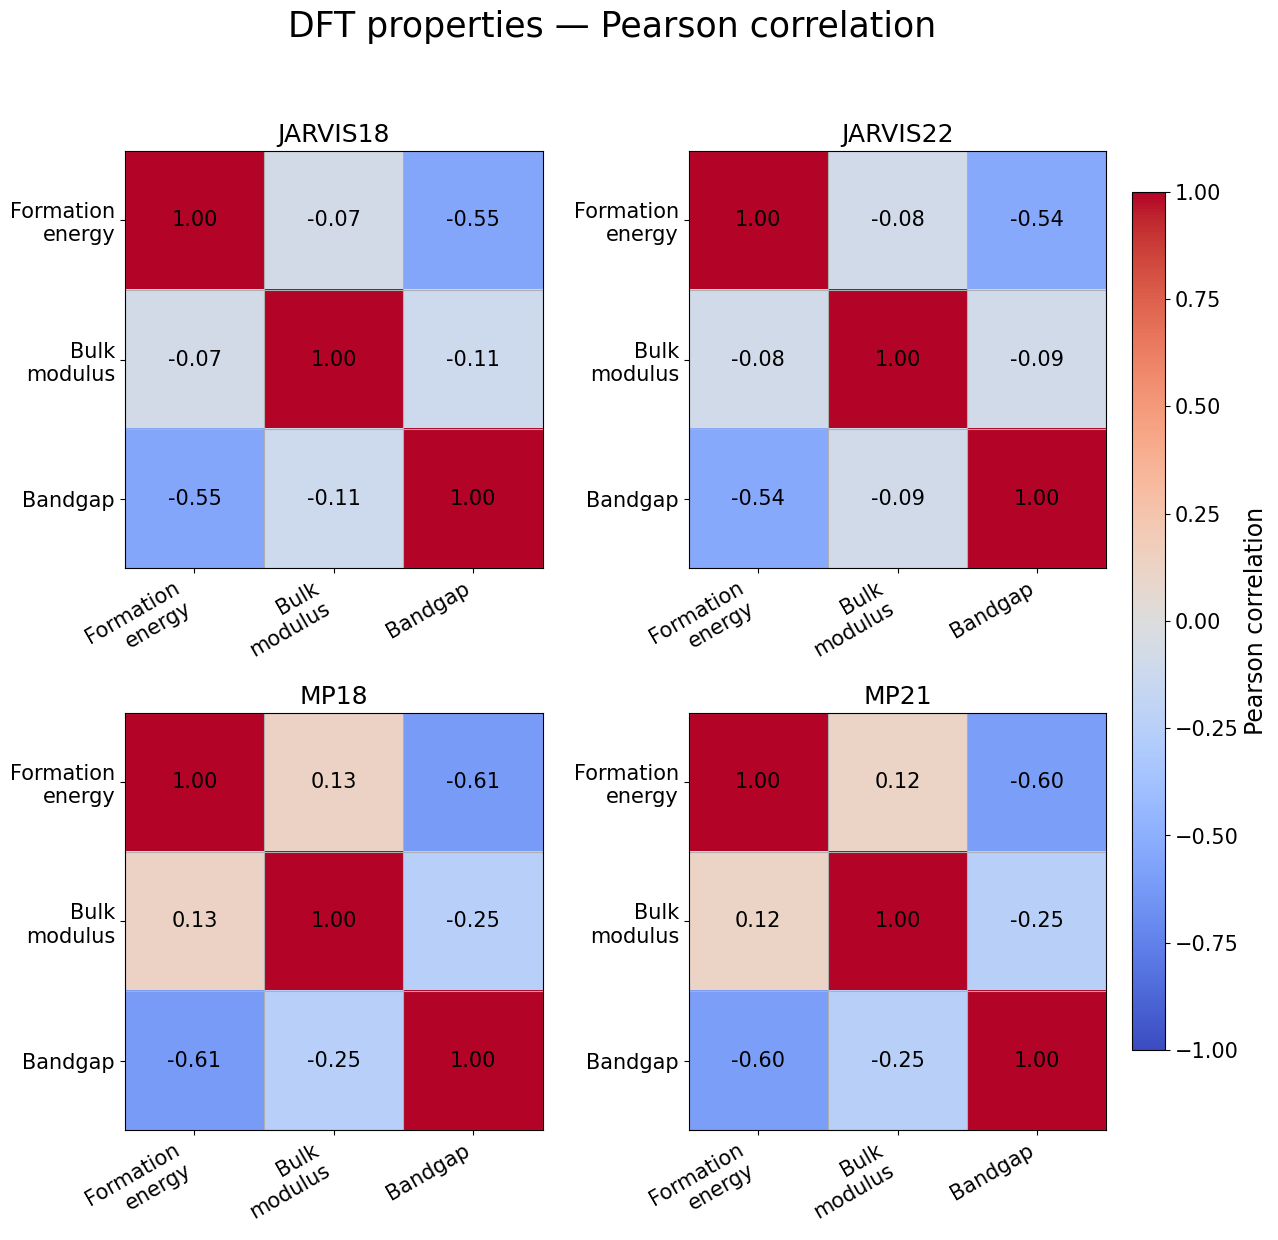

In [9]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


# =============================================================================
# Paths
# =============================================================================

DATASETS = {

    "JARVIS18": Path(
        r"C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES"
        r"\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2"
        r"\WITH_MODIFICATIONS\alldata_ColFilterjarvis18.csv"
    ),

    "JARVIS22": Path(
        r"C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES"
        r"\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2"
        r"\WITH_MODIFICATIONS\alldata_ColFilterjarvis22.csv"
    ),

    "MP18": Path(
        r"C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES"
        r"\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2"
        r"\WITH_MODIFICATIONS\alldata_ColFiltermp18.csv"
    ),

    "MP21": Path(
        r"C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES"
        r"\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2"
        r"\WITH_MODIFICATIONS\alldata_ColFiltermp21.csv"
    ),
}


# =============================================================================
# Properties
# =============================================================================

COLUMNS = [
    "e_form",
    "bulk_modulus",
    "bandgap"
]

DISPLAY_LABELS = {

    "e_form": "Formation\nenergy",

    "bulk_modulus": "Bulk\nmodulus",

    "bandgap": "Bandgap",
}


# =============================================================================
# Heatmap
# =============================================================================

def draw_corr_heatmap(ax, corr, title):

    im = ax.imshow(
        corr.values,
        vmin=-1,
        vmax=1,
        cmap="coolwarm"
    )

    display_names = [
        DISPLAY_LABELS.get(col, col)
        for col in corr.columns
    ]

    # -------------------------------------------------------------------------
    # Axis ticks
    # -------------------------------------------------------------------------

    ax.set_xticks(
        range(len(corr.columns))
    )

    ax.set_yticks(
        range(len(corr.index))
    )

    # Increased from 12 -> 15
    ax.set_xticklabels(
        display_names,
        rotation=30,
        ha="right",
        fontsize=15
    )

    ax.set_yticklabels(
        display_names,
        fontsize=15
    )

    # Same subplot title size as feature correlation plot
    ax.set_title(
        title,
        fontsize=18
    )

    # -------------------------------------------------------------------------
    # Correlation values inside cells
    # -------------------------------------------------------------------------

    for i in range(corr.shape[0]):

        for j in range(corr.shape[1]):

            ax.text(
                j,
                i,
                f"{corr.iloc[i, j]:.2f}",
                ha="center",
                va="center",
                fontsize=15
            )

    # -------------------------------------------------------------------------
    # Grid
    # -------------------------------------------------------------------------

    ax.set_xticks(
        np.arange(-0.5, len(corr.columns), 1),
        minor=True
    )

    ax.set_yticks(
        np.arange(-0.5, len(corr.index), 1),
        minor=True
    )

    ax.grid(
        which="minor",
        linestyle="-",
        linewidth=0.8
    )

    ax.tick_params(
        which="minor",
        bottom=False,
        left=False
    )

    return im


# =============================================================================
# Plot
# =============================================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(13, 13)
)

axes = axes.flatten()


for ax, (dataset_name, path) in zip(
    axes,
    DATASETS.items()
):

    df = pd.read_csv(path)

    data = df[COLUMNS].apply(
        pd.to_numeric,
        errors="coerce"
    )

    corr = data.corr(
        method="pearson"
    )

    im = draw_corr_heatmap(
        ax,
        corr,
        dataset_name
    )


# =============================================================================
# Layout
# =============================================================================

fig.subplots_adjust(
    right=0.88,
    wspace=0.35,
    hspace=0.28
)


# =============================================================================
# Colorbar
# =============================================================================

cbar_ax = fig.add_axes(
    [0.90, 0.18, 0.025, 0.66]
)

cbar = fig.colorbar(
    im,
    cax=cbar_ax
)

# Same as feature-correlation figure
cbar.set_label(
    "Pearson correlation",
    fontsize=17
)

cbar.ax.tick_params(
    labelsize=15
)


# =============================================================================
# Main title
# =============================================================================

fig.suptitle(
    "DFT properties — Pearson correlation",
    fontsize=25
)


# =============================================================================
# Save figure
# =============================================================================

output_path = Path(
    r"C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES"
    r"\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2"
    r"\WITH_MODIFICATIONS\pearson_correlation_heatmaps.png"
)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)


# =============================================================================
# Show
# =============================================================================

plt.show()

Dataset shape: (7770, 165)

Columns found in dataset:
Temperature (K)
HOMO_energy
LUMO_energy
gap_AO
Li
B
C
N
O
F
Na
Mg
Al
Si
P
S
Cl
K
Ca
Sc
Ti
V
Cr
Mn
Fe
Co
Ni
Cu
Zn
Ga
Ge
As
Se
Br
Rb
Sr
Y
Zr
Nb
Mo
Ru
Rh
Pd
Ag
Cd
In
Sn
Sb
Te
I
Cs
Ba
La
Ce
Pr
Nd
Sm
Eu
Gd
Tb
Dy
Ho
Er
Tm
Yb
Lu
Hf
Ta
W
Au
Hg
Tl
Pb
Bi
MagpieData avg_dev MendeleevNumber
MagpieData range AtomicWeight
MagpieData avg_dev AtomicWeight
MagpieData minimum MeltingT
MagpieData range MeltingT
MagpieData mean MeltingT
MagpieData avg_dev MeltingT
MagpieData mode MeltingT
MagpieData avg_dev Column
MagpieData mode Column
MagpieData minimum Row
MagpieData maximum Row
MagpieData range Row
MagpieData mean Row
MagpieData avg_dev Row
MagpieData mode Row
MagpieData maximum CovalentRadius
MagpieData mean CovalentRadius
MagpieData avg_dev CovalentRadius
MagpieData mode CovalentRadius
MagpieData minimum Electronegativity
MagpieData maximum Electronegativity
MagpieData range Electronegativity
MagpieData mean Electronegativity
MagpieData mode Elec

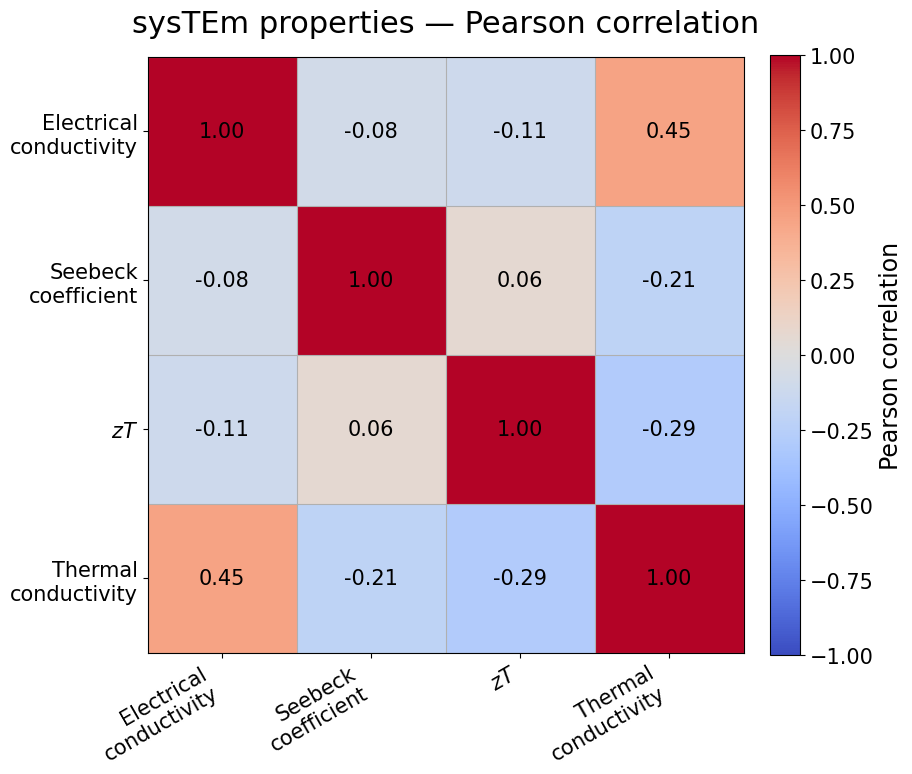

In [12]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


# =============================================================================
# Path
# =============================================================================

DATA_PATH = Path(
    r"C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES"
    r"\PhD Toronto\DatasetGeneration\Better_Acqsition\ThermoElectricNew3"
    r"\WITH_MODIFICATIONS\CLEANED_DATA_AND_FILTERED.csv"
)


# =============================================================================
# Outcome properties
# =============================================================================

COLUMNS = [
    "Electrical Conductivity (S/cm)",
    "Seebeck Coefficient (µV/K)",
    "zT",
    "Total Thermal Conductivity (W/mK)"
]


# Labels used only for visualization
DISPLAY_LABELS = {
    "Electrical Conductivity (S/cm)": "Electrical\nconductivity",
    "Seebeck Coefficient (µV/K)": "Seebeck\ncoefficient",
    "zT": "$zT$",
    "Total Thermal Conductivity (W/mK)": "Thermal\nconductivity",
}


# =============================================================================
# Heatmap
# =============================================================================

def draw_corr_heatmap(ax, corr):

    im = ax.imshow(
        corr.values,
        vmin=-1,
        vmax=1,
        cmap="coolwarm"
    )

    display_names = [
        DISPLAY_LABELS.get(col, col)
        for col in corr.columns
    ]

    # -------------------------------------------------------------------------
    # Axis ticks
    # -------------------------------------------------------------------------

    ax.set_xticks(
        range(len(corr.columns))
    )

    ax.set_yticks(
        range(len(corr.index))
    )

    ax.set_xticklabels(
        display_names,
        rotation=30,
        ha="right",
        fontsize=15
    )

    ax.set_yticklabels(
        display_names,
        fontsize=15
    )

    # -------------------------------------------------------------------------
    # Correlation values inside cells
    # -------------------------------------------------------------------------

    for i in range(corr.shape[0]):

        for j in range(corr.shape[1]):

            value = corr.iloc[i, j]

            ax.text(
                j,
                i,
                f"{value:.2f}",
                ha="center",
                va="center",
                fontsize=15
            )

    # -------------------------------------------------------------------------
    # Grid
    # -------------------------------------------------------------------------

    ax.set_xticks(
        np.arange(-0.5, len(corr.columns), 1),
        minor=True
    )

    ax.set_yticks(
        np.arange(-0.5, len(corr.index), 1),
        minor=True
    )

    ax.grid(
        which="minor",
        linestyle="-",
        linewidth=0.8
    )

    ax.tick_params(
        which="minor",
        bottom=False,
        left=False
    )

    return im


# =============================================================================
# Read data
# =============================================================================

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)

print("\nColumns found in dataset:")
for col in df.columns:
    print(col)


# =============================================================================
# Select outcome properties
# =============================================================================

data = df[COLUMNS].apply(
    pd.to_numeric,
    errors="coerce"
)


# =============================================================================
# Pearson correlation
# =============================================================================

corr = data.corr(
    method="pearson"
)

print("\nPearson correlation matrix:")
print(corr)


# =============================================================================
# Plot
# =============================================================================

fig, ax = plt.subplots(
    figsize=(9, 8)
)

im = draw_corr_heatmap(
    ax,
    corr
)


# =============================================================================
# Colorbar
# =============================================================================

cbar = fig.colorbar(
    im,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

cbar.set_label(
    "Pearson correlation",
    fontsize=17
)

cbar.ax.tick_params(
    labelsize=15
)


# =============================================================================
# Main title
# =============================================================================

ax.set_title(
    "sysTEm properties — Pearson correlation",
    fontsize=22,
    pad=18
)


# =============================================================================
# Layout
# =============================================================================

plt.tight_layout()


# =============================================================================
# Save figure
# =============================================================================

output_path = Path(
    r"C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES"
    r"\PhD Toronto\DatasetGeneration\Better_Acqsition\ThermoElectricNew3"
    r"\WITH_MODIFICATIONS\system_property_pearson_correlation_heatmap.png"
)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

print("\nFigure saved to:")
print(output_path)


# =============================================================================
# Show
# =============================================================================

plt.show()

sysTEm
Original shape: (7770, 165)
Removing outcome columns: ['Electrical Conductivity (S/cm)', 'zT', 'Total Thermal Conductivity (W/mK)']
Final number of features: 161
Maximum absolute feature correlation: 0.8478

Figure saved to:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\ThermoElectricNew3\WITH_MODIFICATIONS\system_feature_pearson_correlation_heatmap.png


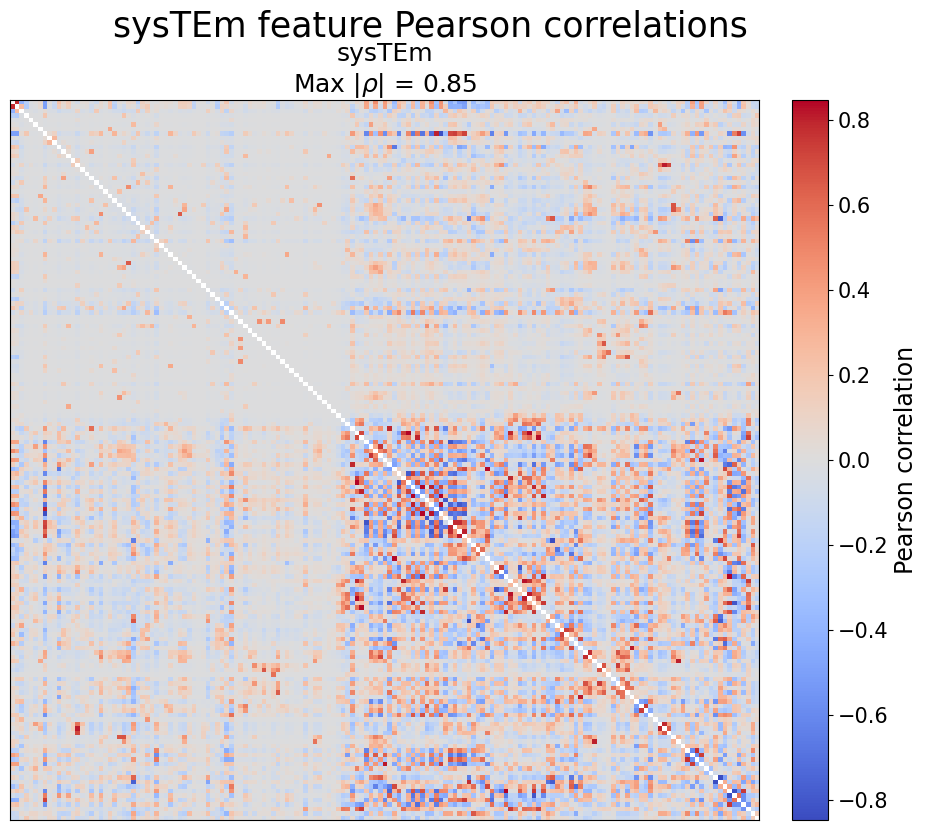

In [13]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


# =============================================================================
# Path
# =============================================================================

DATA_PATH = Path(
    r"C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES"
    r"\PhD Toronto\DatasetGeneration\Better_Acqsition\ThermoElectricNew3"
    r"\WITH_MODIFICATIONS\CLEANED_DATA_AND_FILTERED.csv"
)


# =============================================================================
# Outcome columns to exclude
# =============================================================================

OUTCOME_COLUMNS = [
    "Electrical Conductivity (S/cm)",
    "Seebeck Coefficient (ÂµV/K)",
    "zT",
    "Total Thermal Conductivity (W/mK)",
]


# =============================================================================
# Heatmap function
# =============================================================================

def draw_corr_heatmap(ax, corr, title):

    # Copy correlation matrix
    corr_plot = corr.copy()

    # -------------------------------------------------------------------------
    # Remove diagonal
    # -------------------------------------------------------------------------
    np.fill_diagonal(
        corr_plot.values,
        np.nan
    )

    # -------------------------------------------------------------------------
    # Find maximum absolute off-diagonal correlation
    # -------------------------------------------------------------------------
    max_corr = np.nanmax(
        np.abs(corr_plot.values)
    )

    # Protect against degenerate case
    if max_corr == 0 or np.isnan(max_corr):
        max_corr = 1.0

    # -------------------------------------------------------------------------
    # Colormap
    # -------------------------------------------------------------------------
    cmap = plt.colormaps["coolwarm"].copy()

    # Diagonal appears white
    cmap.set_bad("white")

    # -------------------------------------------------------------------------
    # Heatmap
    # -------------------------------------------------------------------------
    im = ax.imshow(
        corr_plot.values,
        vmin=-max_corr,
        vmax=max_corr,
        cmap=cmap,
        interpolation="none",
        aspect="auto"
    )

    n_features = len(corr.columns)

    # -------------------------------------------------------------------------
    # Axis labels
    # -------------------------------------------------------------------------
    if n_features <= 50:

        ax.set_xticks(
            np.arange(n_features)
        )

        ax.set_yticks(
            np.arange(n_features)
        )

        ax.set_xticklabels(
            corr.columns,
            rotation=90,
            fontsize=6
        )

        ax.set_yticklabels(
            corr.index,
            fontsize=6
        )

    else:

        # Hide labels for large matrices
        ax.set_xticks([])
        ax.set_yticks([])

    # -------------------------------------------------------------------------
    # Title
    # -------------------------------------------------------------------------
    ax.set_title(
        f"{title}\nMax $|\\rho|$ = {max_corr:.2f}",
        fontsize=18
    )

    return im, max_corr


# =============================================================================
# Read dataset
# =============================================================================

df = pd.read_csv(DATA_PATH)

print("=" * 70)
print("sysTEm")
print("=" * 70)

print(f"Original shape: {df.shape}")


# =============================================================================
# Remove first column
#
# This column contains the row indices
# =============================================================================

df = df.iloc[:, 1:].copy()


# =============================================================================
# Remove any remaining unnamed columns
# =============================================================================

unnamed_columns = [
    col
    for col in df.columns
    if str(col).startswith("Unnamed")
]

if unnamed_columns:

    print(
        f"Removing unnamed columns: "
        f"{unnamed_columns}"
    )

    df = df.drop(
        columns=unnamed_columns
    )


# =============================================================================
# Remove outcome properties
#
# We want correlations only between FEATURES
# =============================================================================

outcome_columns_present = [
    col
    for col in OUTCOME_COLUMNS
    if col in df.columns
]

if outcome_columns_present:

    print(
        f"Removing outcome columns: "
        f"{outcome_columns_present}"
    )

    df = df.drop(
        columns=outcome_columns_present
    )


# =============================================================================
# Convert remaining columns to numeric
# =============================================================================

data = df.apply(
    pd.to_numeric,
    errors="coerce"
)


# =============================================================================
# Remove columns that contain only NaN
# =============================================================================

all_nan_columns = data.columns[
    data.isna().all()
].tolist()

if all_nan_columns:

    print(
        f"Removing {len(all_nan_columns)} "
        "non-numeric / completely empty columns."
    )

    data = data.drop(
        columns=all_nan_columns
    )


# =============================================================================
# Remove constant features
#
# Pearson correlation is undefined for constant columns
# =============================================================================

constant_columns = [
    col
    for col in data.columns
    if data[col].nunique(dropna=True) <= 1
]

if constant_columns:

    print(
        f"Removing {len(constant_columns)} "
        "constant features."
    )

    data = data.drop(
        columns=constant_columns
    )


print(
    f"Final number of features: "
    f"{data.shape[1]}"
)


# =============================================================================
# Pearson correlation among FEATURES
# =============================================================================

corr = data.corr(
    method="pearson"
)


# =============================================================================
# Plot
# =============================================================================

fig, ax = plt.subplots(
    figsize=(10, 9)
)

im, max_corr = draw_corr_heatmap(
    ax,
    corr,
    "sysTEm"
)


# =============================================================================
# Colorbar
# =============================================================================

cbar = fig.colorbar(
    im,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

cbar.set_label(
    "Pearson correlation",
    fontsize=17
)

cbar.ax.tick_params(
    labelsize=15
)


# =============================================================================
# Main title
# =============================================================================

fig.suptitle(
    "sysTEm feature Pearson correlations",
    fontsize=25,
    y=0.98
)


# =============================================================================
# Layout
# =============================================================================

fig.subplots_adjust(
    left=0.08,
    right=0.90,
    bottom=0.08,
    top=0.88
)


# =============================================================================
# Print maximum correlation
# =============================================================================

print(
    f"Maximum absolute feature correlation: "
    f"{max_corr:.4f}"
)


# =============================================================================
# Save figure
# =============================================================================

output_path = Path(
    r"C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES"
    r"\PhD Toronto\DatasetGeneration\Better_Acqsition\ThermoElectricNew3"
    r"\WITH_MODIFICATIONS\system_feature_pearson_correlation_heatmap.png"
)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

print("\nFigure saved to:")
print(output_path)


# =============================================================================
# Show
# =============================================================================

plt.show()